## 1. Imports & Configuration

In [1]:
from pathlib import Path
ROOT = Path("../..").resolve()

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from imblearn.ensemble import BalancedRandomForestClassifier
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score, recall_score, precision_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    precision_recall_curve
)

warnings.filterwarnings("ignore")

SEED       = 42
DATA_PATH  = rROOT / 'src/data/processed'

# Boosting ensemble weights for Strategy 1 (XGBoost, CatBoost)
BOOST_WEIGHTS = {"xgb": 0.5, "cat": 0.5}

print("Libraries loaded.")

Libraries loaded.


## 2. Load Data

In [2]:
def load_data(path):
    X_train     = joblib.load(os.path.join(path, "X_train.pkl"))
    y_train     = joblib.load(os.path.join(path, "y_train.pkl"))
    X_val       = joblib.load(os.path.join(path, "X_val.pkl"))
    y_val       = joblib.load(os.path.join(path, "y_val.pkl"))
    X_test      = joblib.load(os.path.join(path, "X_test.pkl"))
    y_test      = joblib.load(os.path.join(path, "y_test.pkl"))
    X_train_res = joblib.load(os.path.join(path, "X_train_res.pkl"))
    y_train_res = joblib.load(os.path.join(path, "y_train_res.pkl"))
    return X_train, y_train, X_val, y_val, X_test, y_test, X_train_res, y_train_res

X_train, y_train, X_val, y_val, X_test, y_test, X_train_res, y_train_res = load_data(DATA_PATH)

print(f"X_train_res : {X_train_res.shape}  |  fraud rate: {y_train_res.mean():.4f}")
print(f"X_val       : {X_val.shape}  |  fraud rate: {y_val.mean():.4f}")
print(f"X_test      : {X_test.shape}  |  fraud rate: {y_test.mean():.4f}")

X_train_res : (452082, 28)  |  fraud rate: 0.0909
X_val       : (89196, 28)  |  fraud rate: 0.0109
X_test      : (89197, 28)  |  fraud rate: 0.0108


## 3. Train Base Models

Each model captures different inductive biases:
- **BRF** – balanced bootstrap + random forest → high recall on original (imbalanced) data
- **LightGBM** – leaf-wise gradient boosting → fast, strong precision
- **XGBoost** – depth-wise gradient boosting with `scale_pos_weight` → precision-recall balance
- **CatBoost** – ordered boosting + symmetric trees → robust to overfitting

Parameters are set to best-known values from individual tuning notebooks.

In [ ]:
# --- 3a. Balanced Random Forest (trained on original imbalanced data) ---
print("Training BRF ...")
brf = BalancedRandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=SEED,
    n_jobs=-1,
    sampling_strategy="auto"
)
brf.fit(X_train, y_train)
print("BRF done.")


Training BRF ...
BRF done.


In [4]:
# --- 3b. LightGBM (trained on SMOTE-resampled data) ---
print("Training LightGBM ...")
lgb_model = lgb.LGBMClassifier(
    n_estimators=1588,
    max_depth=8,
    learning_rate=0.0111,
    num_leaves=262,
    min_child_samples=6,
    subsample=0.7675,
    colsample_bytree=0.5126,
    random_state=SEED,
    n_jobs=-1,
    verbose=-1
)
lgb_model.fit(X_train_res, y_train_res)
print("LightGBM done.")

Training LightGBM ...
LightGBM done.


In [5]:
# --- 3c. XGBoost (trained on SMOTE-resampled data) ---
print("Training XGBoost ...")
xgb_model = xgb.XGBClassifier(
    n_estimators=1373,
    max_depth=8,
    learning_rate=0.0070,
    subsample=0.9973,
    colsample_bytree=0.5226,
    min_child_weight=13,
    scale_pos_weight=5.08,
    random_state=SEED,
    n_jobs=-1,
    tree_method="hist",
    eval_metric="aucpr",
    verbosity=0
)
xgb_model.fit(X_train_res, y_train_res)
print("XGBoost done.")

Training XGBoost ...
XGBoost done.


In [6]:
# --- 3d. CatBoost (trained on SMOTE-resampled data) ---
print("Training CatBoost ...")
cat_model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    l2_leaf_reg=3.0,
    subsample=0.8,
    colsample_bylevel=0.8,
    random_seed=SEED,
    eval_metric="AUC",
    verbose=0
)
cat_model.fit(X_train_res, y_train_res)
print("CatBoost done.")

Training CatBoost ...
CatBoost done.


## 4. Base Model Evaluation

Generate probability predictions and key metrics for each base model on the **test set**.

In [7]:
def calculate_metrics(y_true, y_pred, y_prob, label=""):
    metrics = {
        "F1":        round(f1_score(y_true, y_pred), 4),
        "Recall":    round(recall_score(y_true, y_pred), 4),
        "Precision": round(precision_score(y_true, y_pred), 4),
        "ROC-AUC":   round(roc_auc_score(y_true, y_prob), 4),
        "PR-AUC":    round(average_precision_score(y_true, y_prob), 4),
    }
    if label:
        print(f"\n=== {label} ===")
        for k, v in metrics.items():
            print(f"  {k}: {v}")
    return metrics

# --- Generate probabilities on val and test ---
brf_val_probs = brf.predict_proba(X_val)[:, 1]
lgb_val_probs = lgb_model.predict_proba(X_val)[:, 1]
xgb_val_probs = xgb_model.predict_proba(X_val)[:, 1]
cat_val_probs = cat_model.predict_proba(X_val)[:, 1]

brf_test_probs = brf.predict_proba(X_test)[:, 1]
lgb_test_probs = lgb_model.predict_proba(X_test)[:, 1]
xgb_test_probs = xgb_model.predict_proba(X_test)[:, 1]
cat_test_probs = cat_model.predict_proba(X_test)[:, 1]

# --- Test predictions at 0.5 threshold ---
brf_test_preds = (brf_test_probs >= 0.5).astype(int)
lgb_test_preds = (lgb_test_probs >= 0.5).astype(int)
xgb_test_preds = (xgb_test_probs >= 0.5).astype(int)
cat_test_preds = (cat_test_probs >= 0.5).astype(int)

brf_metrics  = calculate_metrics(y_test, brf_test_preds,  brf_test_probs,  "BRF (Test)")
lgb_metrics  = calculate_metrics(y_test, lgb_test_preds,  lgb_test_probs,  "LightGBM (Test)")
xgb_metrics  = calculate_metrics(y_test, xgb_test_preds,  xgb_test_probs,  "XGBoost (Test)")
cat_metrics  = calculate_metrics(y_test, cat_test_preds,  cat_test_probs,  "CatBoost (Test)")

base_df = pd.DataFrame(
    [brf_metrics, lgb_metrics, xgb_metrics, cat_metrics],
    index=["BRF", "LightGBM", "XGBoost", "CatBoost"]
)
print("\nBase Model Summary (Test Set):")
display(base_df)


=== BRF (Test) ===
  F1: 0.5851
  Recall: 0.9886
  Precision: 0.4155
  ROC-AUC: 0.9984
  PR-AUC: 0.8871

=== LightGBM (Test) ===
  F1: 0.8221
  Recall: 0.7349
  Precision: 0.9327
  ROC-AUC: 0.9989
  PR-AUC: 0.9323

=== XGBoost (Test) ===
  F1: 0.8357
  Recall: 0.8669
  Precision: 0.8066
  ROC-AUC: 0.9989
  PR-AUC: 0.9304

=== CatBoost (Test) ===
  F1: 0.8192
  Recall: 0.7464
  Precision: 0.9077
  ROC-AUC: 0.9987
  PR-AUC: 0.9203

Base Model Summary (Test Set):


,F1,Recall,Precision,ROC-AUC,PR-AUC
BRF,0.5851,0.9886,0.4155,0.9984,0.8871
LightGBM,0.8221,0.7349,0.9327,0.9989,0.9323
XGBoost,0.8357,0.8669,0.8066,0.9989,0.9304
CatBoost,0.8192,0.7464,0.9077,0.9987,0.9203


## Strategy 1: Hybrid "Funnel" System (Two-Stage Filtering)

### Design Rationale

BRF achieves ~0.98 Recall by design (balanced bootstrap forces equal representation of fraud). However, this produces many False Positives. Boosting models are more conservative and precise.

The funnel exploits both strengths:

```
All Transactions
       |
  [Stage 1: BRF Net]
    |           |
  Flagged    Not Flagged --> Legitimate (0)
    |
  [Stage 2: XGB+CAT Boosting Ensemble]
    |              |
  Confirmed    Not Confirmed
    |              |
 HIGH-RISK     REVIEW REQUIRED
 FRAUD (2)         (1)
```

**Output labels:**
- `0` = Legitimate (not flagged by BRF)
- `1` = Review Required (BRF flags, Boosting does not confirm)
- `2` = High-Risk Fraud (BRF flags AND Boosting confirms)

In [8]:
def hybrid_funnel_predict(X, brf_model, xgb_m, cat_m,
                           brf_threshold=0.5,
                           boost_threshold=0.5,
                           xgb_weight=0.5, cat_weight=0.5):
    """
    Returns a 3-class label array:
      0 = Legitimate
      1 = Review Required (BRF flag, no boosting confirmation)
      2 = High-Risk Fraud  (BRF flag + boosting confirmation)
    """
    brf_probs   = brf_model.predict_proba(X)[:, 1]
    brf_flags   = (brf_probs >= brf_threshold)

    xgb_probs   = xgb_m.predict_proba(X)[:, 1]
    cat_probs   = cat_m.predict_proba(X)[:, 1]
    boost_probs = xgb_weight * xgb_probs + cat_weight * cat_probs
    boost_flags = (boost_probs >= boost_threshold)

    labels = np.zeros(len(X), dtype=int)
    labels[brf_flags & ~boost_flags] = 1   # Review Required
    labels[brf_flags &  boost_flags] = 2   # High-Risk Fraud
    return labels, brf_probs, boost_probs


def funnel_to_binary(funnel_labels, mode="conservative"):
    """
    Convert 3-class funnel output to binary fraud label.
    mode='conservative' : only label=2 is fraud
    mode='aggressive'   : label=1 and label=2 are both fraud
    """
    if mode == "conservative":
        return (funnel_labels == 2).astype(int)
    return (funnel_labels >= 1).astype(int)


# --- Run Hybrid Funnel on test set ---
funnel_labels_test, brf_p_test, boost_p_test = hybrid_funnel_predict(
    X_test, brf, xgb_model, cat_model,
    brf_threshold=0.4,
    boost_threshold=0.5,
    xgb_weight=BOOST_WEIGHTS["xgb"],
    cat_weight=BOOST_WEIGHTS["cat"]
)

n_total     = len(funnel_labels_test)
n_legit     = (funnel_labels_test == 0).sum()
n_review    = (funnel_labels_test == 1).sum()
n_high_risk = (funnel_labels_test == 2).sum()

print(f"Legitimate      (label 0) : {n_legit:>7,}  ({100*n_legit/n_total:.2f}%)")
print(f"Review Required (label 1) : {n_review:>7,}  ({100*n_review/n_total:.2f}%)")
print(f"High-Risk Fraud (label 2) : {n_high_risk:>7,}  ({100*n_high_risk/n_total:.2f}%)")
print(f"Actual fraud in test set  : {int(y_test.sum()):>7,}  ({100*y_test.mean():.2f}%)")

Legitimate      (label 0) :  86,672  (97.17%)
Review Required (label 1) :   1,647  (1.85%)
High-Risk Fraud (label 2) :     878  (0.98%)
Actual fraud in test set  :     962  (1.08%)


In [9]:
# --- Evaluate both funnel modes ---
funnel_conservative_preds = funnel_to_binary(funnel_labels_test, mode="conservative")
funnel_aggressive_preds   = funnel_to_binary(funnel_labels_test, mode="aggressive")

# Use average of BRF and boosting probabilities for PRAUC
funnel_probs = 0.4 * brf_p_test + 0.6 * boost_p_test

funnel_cons_metrics = calculate_metrics(
    y_test, funnel_conservative_preds, funnel_probs,
    "Hybrid Funnel – Conservative (label=2 only)"
)
funnel_agg_metrics = calculate_metrics(
    y_test, funnel_aggressive_preds, funnel_probs,
    "Hybrid Funnel – Aggressive (label>=1)"
)


=== Hybrid Funnel – Conservative (label=2 only) ===
  F1: 0.8337
  Recall: 0.7973
  Precision: 0.8736
  ROC-AUC: 0.9989
  PR-AUC: 0.9283

=== Hybrid Funnel – Aggressive (label>=1) ===
  F1: 0.5489
  Recall: 0.9948
  Precision: 0.379
  ROC-AUC: 0.9989
  PR-AUC: 0.9283


## Strategy 2: Weighted Stacking (Probability Fusion)

### Design Rationale

Each base model's probability output encodes complementary information:
- **BRF** probability is high for transactions that look anomalous relative to balanced classes
- **LightGBM/CatBoost** probabilities are high only for strongly anomalous patterns

A **Logistic Regression meta-learner** trained on validation-set probability outputs learns:
1. How much to trust each model's signal
2. How to combine them to maximize discrimination

**Stacking protocol:**
1. Train 4 base models on `X_train_res` (already done)
2. Generate `P_fraud` for all 4 models on `X_val` → meta-features for meta-learner training
3. Train LogisticRegression meta-learner on `[P_brf, P_lgb, P_xgb, P_cat]` → `y_val`
4. Generate `P_fraud` for all 4 models on `X_test` → feed into meta-learner for final prediction

In [10]:
# --- Build meta-features from validation set ---
meta_X_val = np.column_stack([
    brf_val_probs,
    lgb_val_probs,
    xgb_val_probs,
    cat_val_probs
])

meta_X_test = np.column_stack([
    brf_test_probs,
    lgb_test_probs,
    xgb_test_probs,
    cat_test_probs
])

meta_feature_names = ["P_BRF", "P_LGB", "P_XGB", "P_CAT"]

print("Meta-feature matrix shape (val) :", meta_X_val.shape)
print("Meta-feature matrix shape (test):", meta_X_test.shape)

Meta-feature matrix shape (val) : (89196, 4)
Meta-feature matrix shape (test): (89197, 4)


In [11]:
# --- Train Logistic Regression meta-learner ---
scaler     = StandardScaler()
meta_X_val_scaled  = scaler.fit_transform(meta_X_val)
meta_X_test_scaled = scaler.transform(meta_X_test)

meta_learner = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=SEED
)
meta_learner.fit(meta_X_val_scaled, y_val)

# Print learned coefficients (model trust weights)
coef_df = pd.DataFrame(
    {"Feature": meta_feature_names, "Coefficient": meta_learner.coef_[0]}
).sort_values("Coefficient", ascending=False)

print("Meta-learner coefficients (higher = more trusted for fraud detection):")
display(coef_df.reset_index(drop=True))

Meta-learner coefficients (higher = more trusted for fraud detection):


,Feature,Coefficient
0,P_BRF,1.388319
1,P_CAT,0.180437
2,P_LGB,0.172543
3,P_XGB,-0.013856


In [12]:
# --- Stacking predictions on test set ---
stack_test_probs = meta_learner.predict_proba(meta_X_test_scaled)[:, 1]
stack_test_preds = (stack_test_probs >= 0.5).astype(int)

stack_metrics = calculate_metrics(
    y_test, stack_test_preds, stack_test_probs,
    "Weighted Stacking – LR Meta-Learner (Test)"
)


=== Weighted Stacking – LR Meta-Learner (Test) ===
  F1: 0.6062
  Recall: 0.9834
  Precision: 0.4382
  ROC-AUC: 0.9988
  PR-AUC: 0.926


## 5. Comprehensive Comparison

In [13]:
comparison_df = pd.DataFrame(
    [
        brf_metrics,
        lgb_metrics,
        xgb_metrics,
        cat_metrics,
        funnel_cons_metrics,
        funnel_agg_metrics,
        stack_metrics
    ],
    index=[
        "BRF (Base)",
        "LightGBM (Base)",
        "XGBoost (Base)",
        "CatBoost (Base)",
        "Funnel – Conservative",
        "Funnel – Aggressive",
        "Weighted Stacking"
    ]
)

print("\nFull Comparison Table (Test Set):")
display(comparison_df)


Full Comparison Table (Test Set):


,F1,Recall,Precision,ROC-AUC,PR-AUC
BRF (Base),0.5851,0.9886,0.4155,0.9984,0.8871
LightGBM (Base),0.8221,0.7349,0.9327,0.9989,0.9323
XGBoost (Base),0.8357,0.8669,0.8066,0.9989,0.9304
CatBoost (Base),0.8192,0.7464,0.9077,0.9987,0.9203
Funnel – Conservative,0.8337,0.7973,0.8736,0.9989,0.9283
Funnel – Aggressive,0.5489,0.9948,0.3790,0.9989,0.9283
Weighted Stacking,0.6062,0.9834,0.4382,0.9988,0.9260


## 6. Visualization

### 6a. Grouped Bar Chart – Metrics Comparison

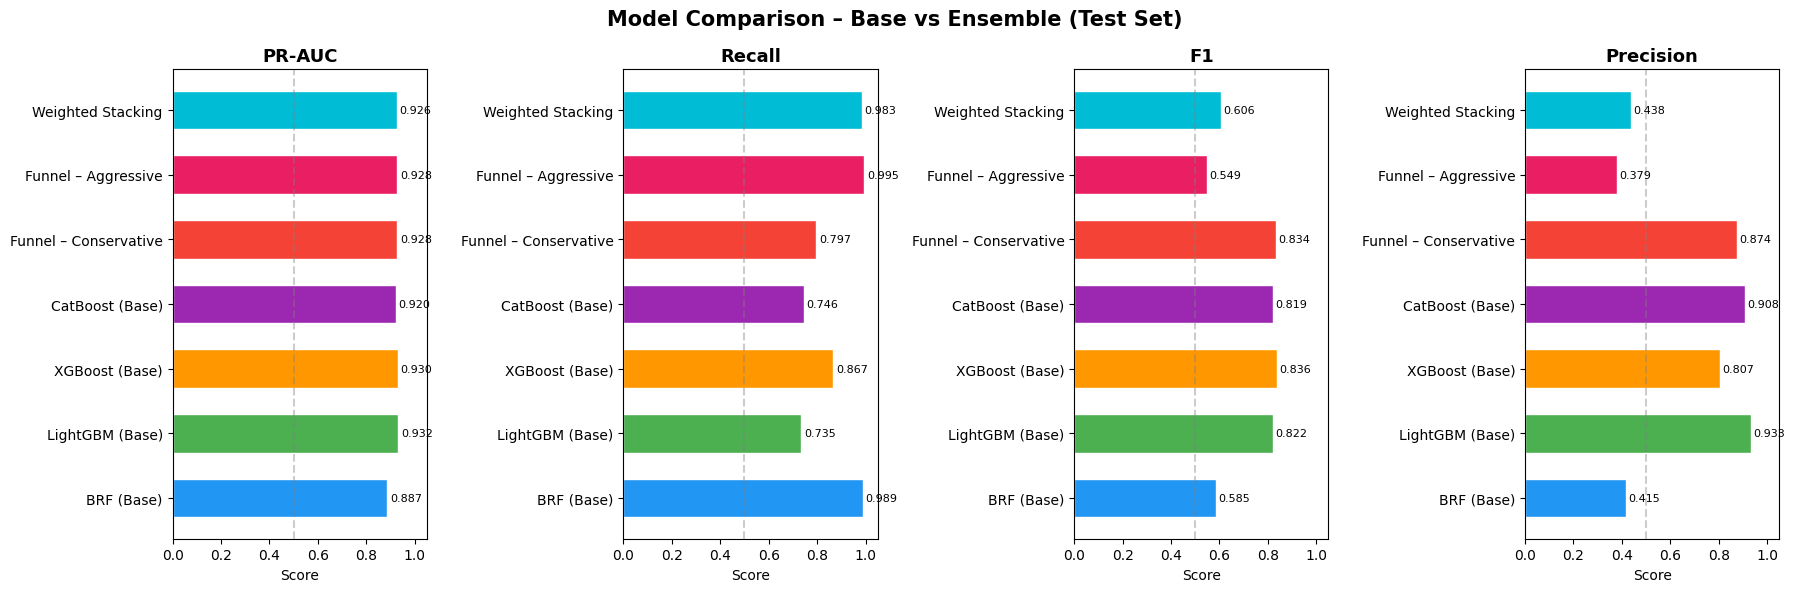

In [14]:
metrics_to_plot = ["PR-AUC", "Recall", "F1", "Precision"]
colors = ["#2196F3", "#4CAF50", "#FF9800", "#9C27B0",
          "#F44336", "#E91E63", "#00BCD4"]

fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(18, 6))
models    = comparison_df.index.tolist()

for ax, metric in zip(axes, metrics_to_plot):
    vals   = comparison_df[metric].values
    bars   = ax.barh(models, vals, color=colors, edgecolor="white", height=0.6)
    ax.set_xlim(0, 1.05)
    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_xlabel("Score")
    ax.axvline(x=0.5, color="gray", linestyle="--", alpha=0.4)
    for bar, val in zip(bars, vals):
        ax.text(val + 0.01, bar.get_y() + bar.get_height() / 2,
                f"{val:.3f}", va="center", fontsize=8)

fig.suptitle("Model Comparison – Base vs Ensemble (Test Set)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### 6b. Precision-Recall Curves – All Models

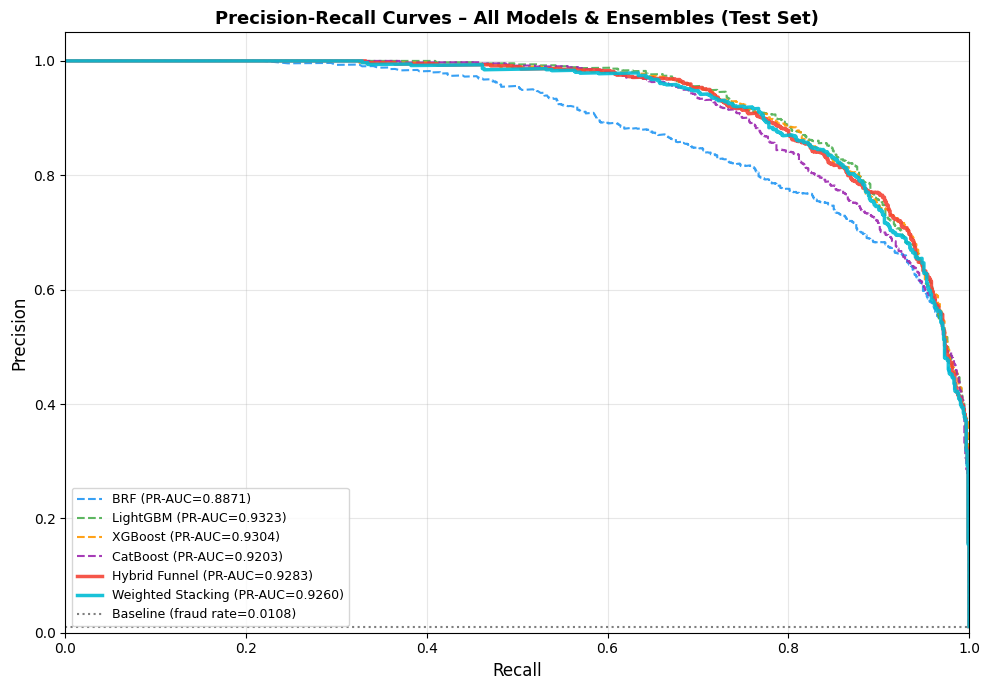

In [16]:
fig, ax = plt.subplots(figsize=(10, 7))

prob_sets = [
    (brf_test_probs,   "BRF",                   "#2196F3", "--"),
    (lgb_test_probs,   "LightGBM",               "#4CAF50", "--"),
    (xgb_test_probs,   "XGBoost",                "#FF9800", "--"),
    (cat_test_probs,   "CatBoost",               "#9C27B0", "--"),
    (funnel_probs,     "Hybrid Funnel",          "#F44336", "-"),
    (stack_test_probs, "Weighted Stacking",      "#00BCD4", "-"),
]

for probs, label, color, ls in prob_sets:
    prec, rec, _ = precision_recall_curve(y_test, probs)
    prauc = average_precision_score(y_test, probs)
    lw = 2.5 if ls == "-" else 1.5
    ax.plot(rec, prec, color=color, linestyle=ls, linewidth=lw,
            label=f"{label} (PR-AUC={prauc:.4f})", alpha=0.9)

ax.axhline(y=y_test.mean(), color="black", linestyle=":", alpha=0.5,
           label=f"Baseline (fraud rate={y_test.mean():.4f})")
ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Precision-Recall Curves – All Models & Ensembles (Test Set)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=9, loc="lower left")
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.05])
plt.tight_layout()
plt.show()

### 6c. Confusion Matrices – All Strategies

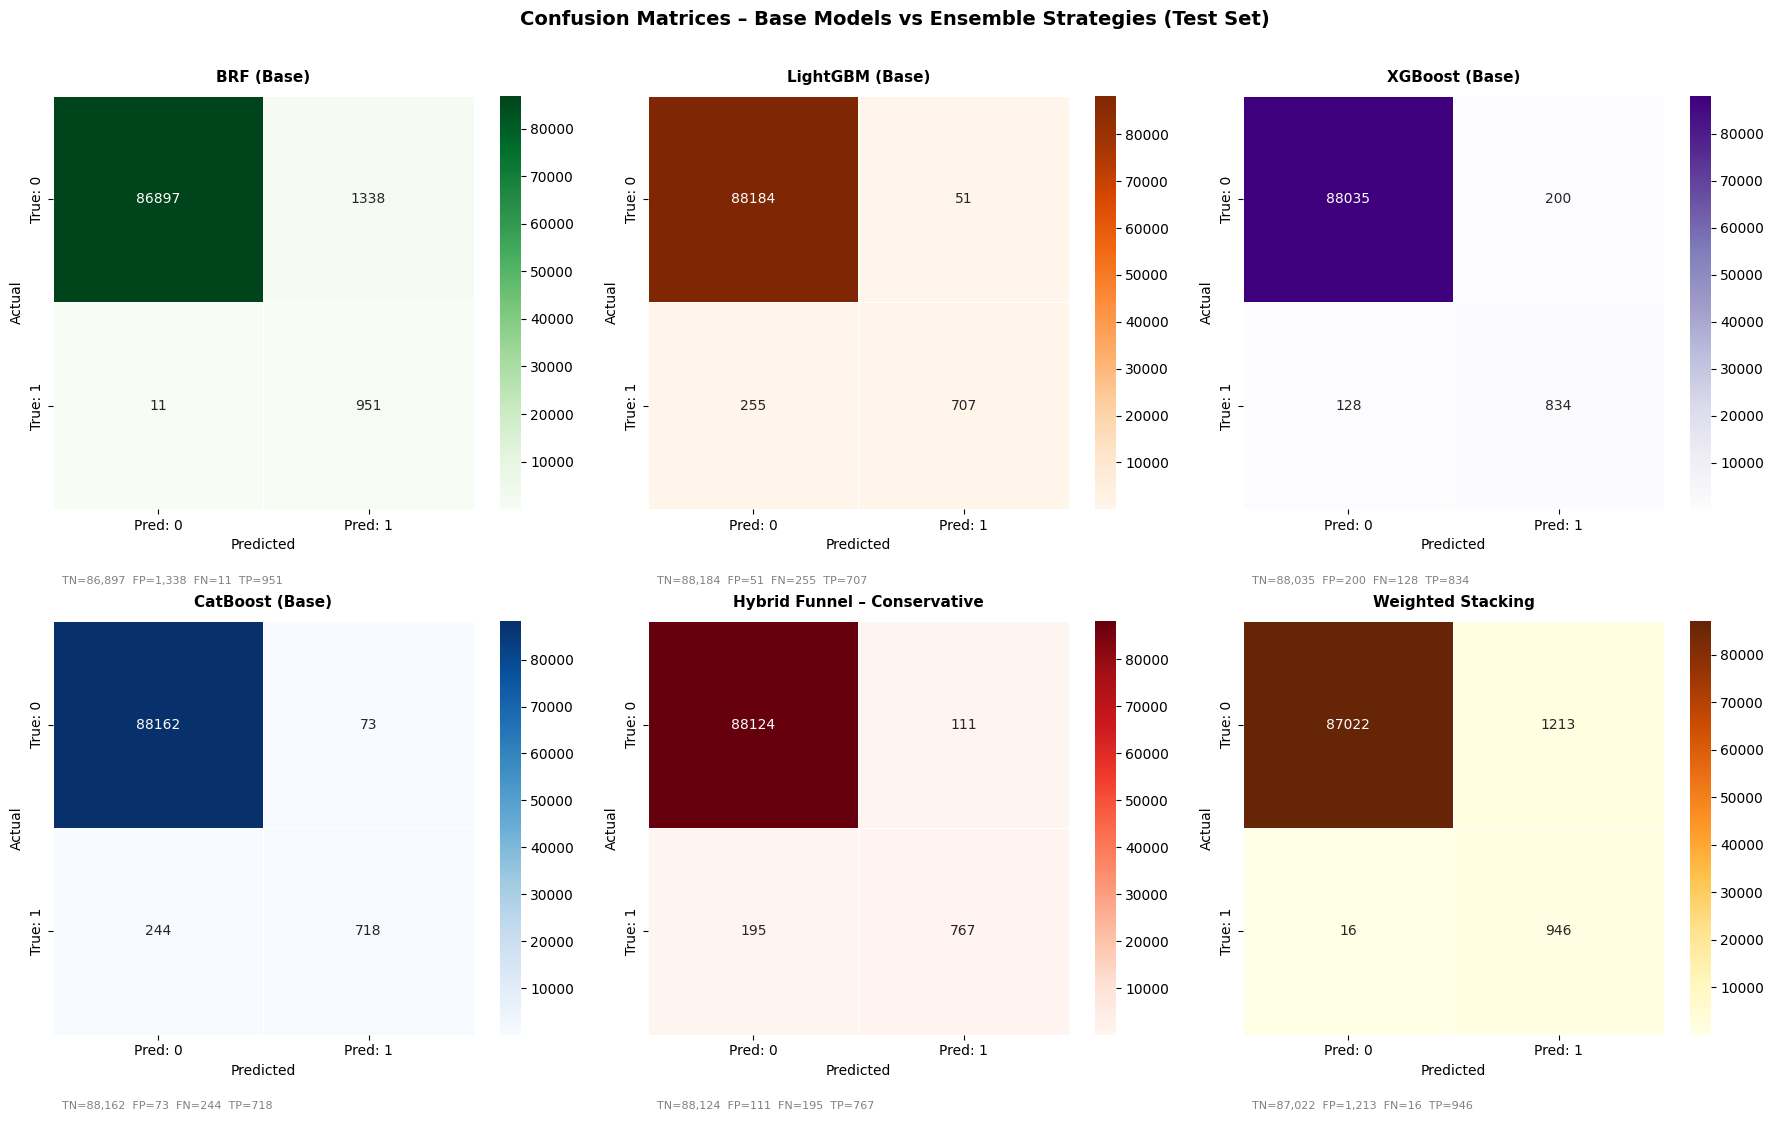

In [17]:
def plot_confusion(ax, y_true, y_pred, title, cmap="Blues"):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap,
                xticklabels=["Pred: 0", "Pred: 1"],
                yticklabels=["True: 0", "True: 1"],
                ax=ax, linewidths=0.5)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    tn, fp, fn, tp = cm.ravel()
    ax.text(0.02, -0.18, f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}",
            transform=ax.transAxes, fontsize=8, color="gray")

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

plot_confusion(axes[0, 0], y_test, brf_test_preds,                "BRF (Base)",                    "Greens")
plot_confusion(axes[0, 1], y_test, lgb_test_preds,                "LightGBM (Base)",               "Oranges")
plot_confusion(axes[0, 2], y_test, xgb_test_preds,                "XGBoost (Base)",                "Purples")
plot_confusion(axes[1, 0], y_test, cat_test_preds,                "CatBoost (Base)",               "Blues")
plot_confusion(axes[1, 1], y_test, funnel_cons_metrics and
               funnel_conservative_preds,                          "Hybrid Funnel – Conservative",  "Reds")
plot_confusion(axes[1, 2], y_test, stack_test_preds,              "Weighted Stacking",             "YlOrBr")

fig.suptitle("Confusion Matrices – Base Models vs Ensemble Strategies (Test Set)",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### 6d. Hybrid Funnel Decision Flow Visualization

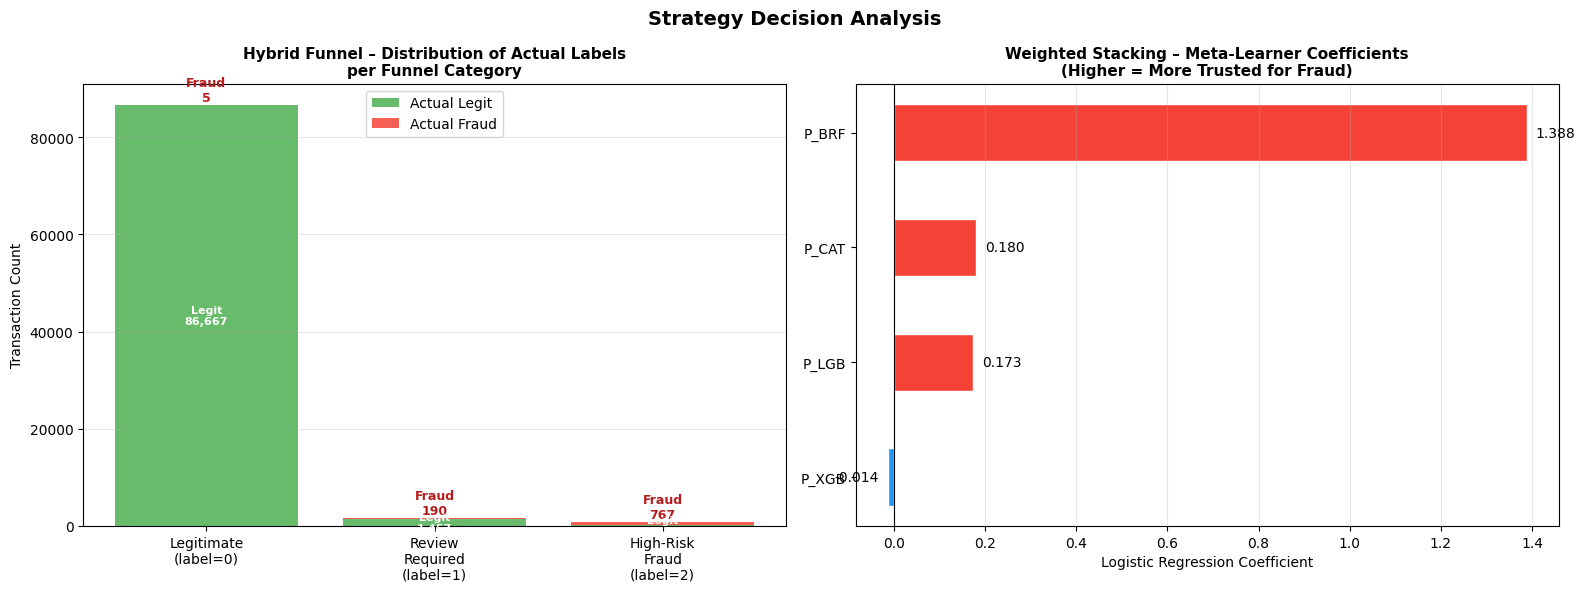

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Left: Sankey-style flow bar chart ---
ax = axes[0]
actual_fraud  = int(y_test.sum())
actual_legit  = int((y_test == 0).sum())

# Among the test set, break down by funnel label
fraud_in_legit     = int(((funnel_labels_test == 0) & (y_test == 1)).sum())
fraud_in_review    = int(((funnel_labels_test == 1) & (y_test == 1)).sum())
fraud_in_high_risk = int(((funnel_labels_test == 2) & (y_test == 1)).sum())

legit_in_legit     = int(((funnel_labels_test == 0) & (y_test == 0)).sum())
legit_in_review    = int(((funnel_labels_test == 1) & (y_test == 0)).sum())
legit_in_high_risk = int(((funnel_labels_test == 2) & (y_test == 0)).sum())

categories = ["Legitimate\n(label=0)", "Review\nRequired\n(label=1)", "High-Risk\nFraud\n(label=2)"]
fraud_counts = [fraud_in_legit, fraud_in_review, fraud_in_high_risk]
legit_counts = [legit_in_legit, legit_in_review, legit_in_high_risk]

x = np.arange(3)
ax.bar(x, legit_counts, label="Actual Legit", color="#4CAF50", alpha=0.85)
ax.bar(x, fraud_counts, bottom=legit_counts, label="Actual Fraud", color="#F44336", alpha=0.85)

for i, (f, l) in enumerate(zip(fraud_counts, legit_counts)):
    ax.text(i, l + f + 200, f"Fraud\n{f}", ha="center", va="bottom",
            fontsize=9, color="#B71C1C", fontweight="bold")
    ax.text(i, l / 2, f"Legit\n{l:,}", ha="center", va="center",
            fontsize=8, color="white", fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=10)
ax.set_ylabel("Transaction Count")
ax.set_title("Hybrid Funnel – Distribution of Actual Labels\nper Funnel Category",
             fontsize=11, fontweight="bold")
ax.legend(loc="upper center")
ax.grid(axis="y", alpha=0.3)

# --- Right: Meta-learner coefficient chart ---
ax2 = axes[1]
coef_sorted = coef_df.sort_values("Coefficient")
colors_coef = ["#F44336" if c > 0 else "#2196F3" for c in coef_sorted["Coefficient"]]
bars = ax2.barh(coef_sorted["Feature"], coef_sorted["Coefficient"],
                color=colors_coef, edgecolor="white", height=0.5)
ax2.axvline(x=0, color="black", linewidth=0.8)
ax2.set_xlabel("Logistic Regression Coefficient")
ax2.set_title("Weighted Stacking – Meta-Learner Coefficients\n(Higher = More Trusted for Fraud)",
              fontsize=11, fontweight="bold")
for bar, val in zip(bars, coef_sorted["Coefficient"]):
    ax2.text(val + 0.02 if val >= 0 else val - 0.02,
             bar.get_y() + bar.get_height() / 2,
             f"{val:.3f}", va="center",
             ha="left" if val >= 0 else "right", fontsize=10)
ax2.grid(axis="x", alpha=0.3)

fig.suptitle("Strategy Decision Analysis", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 6e. Radar Chart – Strategy Profile

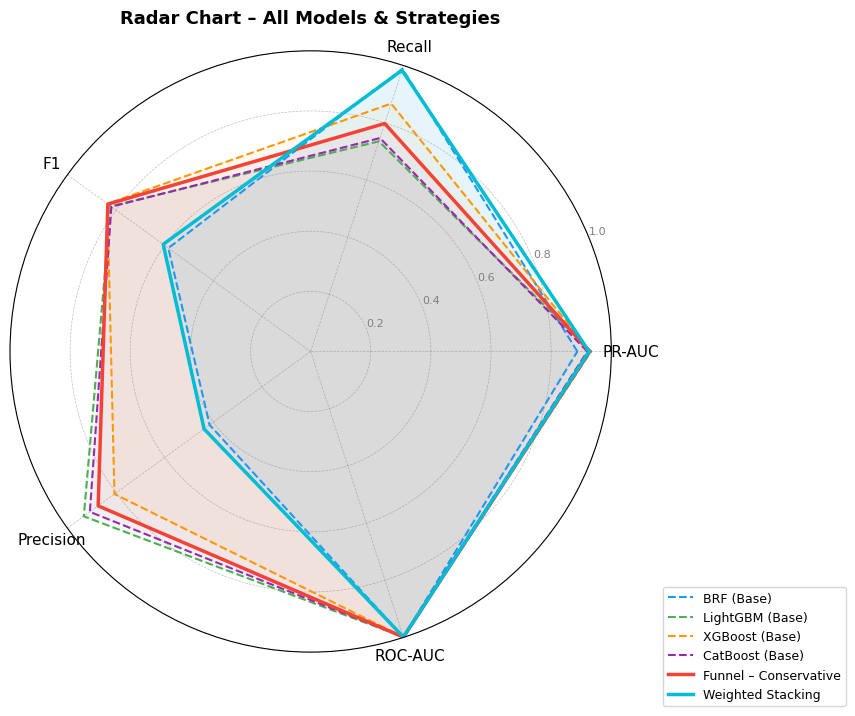

In [19]:
from matplotlib.patches import FancyArrowPatch

radar_metrics = ["PR-AUC", "Recall", "F1", "Precision", "ROC-AUC"]
radar_models  = [
    ("BRF (Base)",           "#2196F3", "--"),
    ("LightGBM (Base)",      "#4CAF50", "--"),
    ("XGBoost (Base)",       "#FF9800", "--"),
    ("CatBoost (Base)",      "#9C27B0", "--"),
    ("Funnel – Conservative","#F44336", "-"),
    ("Weighted Stacking",    "#00BCD4", "-"),
]

N      = len(radar_metrics)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))

for model_name, color, ls in radar_models:
    values = [comparison_df.loc[model_name, m] for m in radar_metrics]
    values += values[:1]
    lw = 2.5 if ls == "-" else 1.5
    ax.plot(angles, values, color=color, linewidth=lw, linestyle=ls, label=model_name)
    ax.fill(angles, values, color=color, alpha=0.05)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_metrics, fontsize=11)
ax.set_ylim(0, 1.0)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=8, color="gray")
ax.grid(color="gray", linestyle="--", linewidth=0.5, alpha=0.5)
ax.set_title("Radar Chart – All Models & Strategies", fontsize=13, fontweight="bold", pad=20)
ax.legend(loc="lower right", bbox_to_anchor=(1.4, -0.1), fontsize=9)

plt.tight_layout()
plt.show()

## 7. False Negative Analysis

False Negatives (missed fraud) are the most costly error in financial fraud detection. This cell quantifies how each strategy reduces FN count versus the best single base model.

False Negative & False Positive Breakdown (Test Set):


,TN,FP,FN,TP,Missed Fraud,False Alarms
Model,,,,,,
BRF (Base),86897,1338,11,951,11,1338
LightGBM (Base),88184,51,255,707,255,51
XGBoost (Base),88035,200,128,834,128,200
CatBoost (Base),88162,73,244,718,244,73
Funnel – Conservative,88124,111,195,767,195,111
Funnel – Aggressive,86667,1568,5,957,5,1568
Weighted Stacking,87022,1213,16,946,16,1213


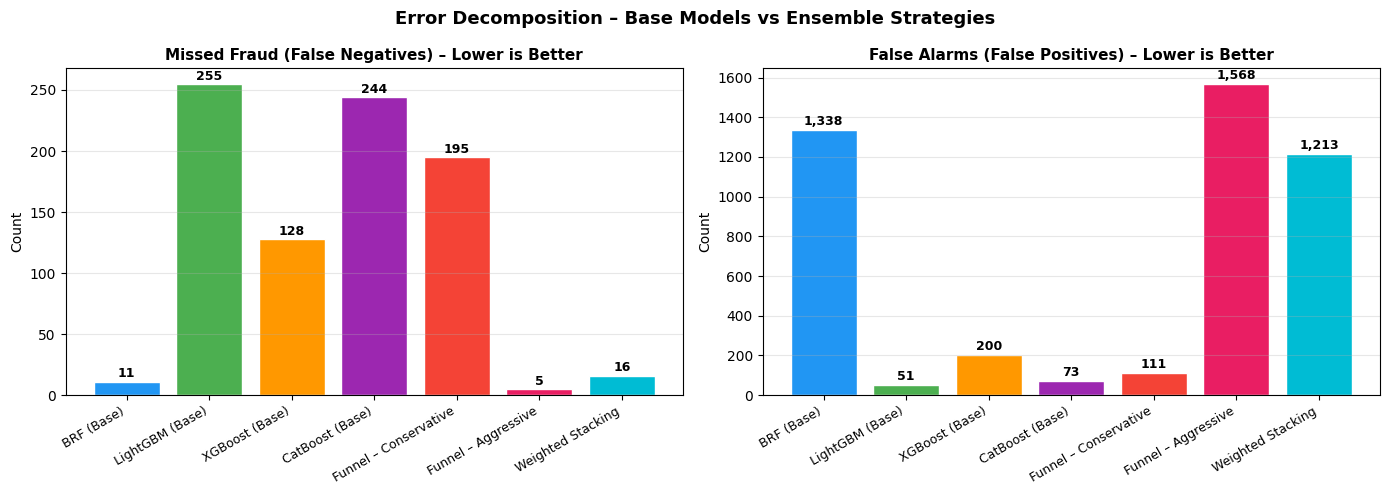

In [20]:
def fn_fp_breakdown(y_true, y_pred, label):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return {"Model": label, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Missed Fraud": fn, "False Alarms": fp}

breakdown_rows = [
    fn_fp_breakdown(y_test, brf_test_preds,              "BRF (Base)"),
    fn_fp_breakdown(y_test, lgb_test_preds,              "LightGBM (Base)"),
    fn_fp_breakdown(y_test, xgb_test_preds,              "XGBoost (Base)"),
    fn_fp_breakdown(y_test, cat_test_preds,              "CatBoost (Base)"),
    fn_fp_breakdown(y_test, funnel_conservative_preds,   "Funnel – Conservative"),
    fn_fp_breakdown(y_test, funnel_aggressive_preds,     "Funnel – Aggressive"),
    fn_fp_breakdown(y_test, stack_test_preds,            "Weighted Stacking"),
]

breakdown_df = pd.DataFrame(breakdown_rows).set_index("Model")
print("False Negative & False Positive Breakdown (Test Set):")
display(breakdown_df)

# Bar chart: Missed Fraud vs False Alarms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bd = breakdown_df.reset_index()

palette = ["#2196F3", "#4CAF50", "#FF9800", "#9C27B0", "#F44336", "#E91E63", "#00BCD4"]

ax1 = axes[0]
bars1 = ax1.bar(bd["Model"], bd["Missed Fraud"], color=palette, edgecolor="white")
ax1.set_title("Missed Fraud (False Negatives) – Lower is Better",
              fontsize=11, fontweight="bold")
ax1.set_ylabel("Count")
ax1.set_xticklabels(bd["Model"], rotation=30, ha="right", fontsize=9)
ax1.grid(axis="y", alpha=0.3)
for bar, val in zip(bars1, bd["Missed Fraud"]):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
             str(val), ha="center", va="bottom", fontsize=9, fontweight="bold")

ax2 = axes[1]
bars2 = ax2.bar(bd["Model"], bd["False Alarms"], color=palette, edgecolor="white")
ax2.set_title("False Alarms (False Positives) – Lower is Better",
              fontsize=11, fontweight="bold")
ax2.set_ylabel("Count")
ax2.set_xticklabels(bd["Model"], rotation=30, ha="right", fontsize=9)
ax2.grid(axis="y", alpha=0.3)
for bar, val in zip(bars2, bd["False Alarms"]):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
             f"{val:,}", ha="center", va="bottom", fontsize=9, fontweight="bold")

fig.suptitle("Error Decomposition – Base Models vs Ensemble Strategies",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 8. Summary & Conclusions

### Key Findings

**Strategy 1 – Hybrid Funnel:**
- The BRF net captures virtually all fraud at Stage 1 (high recall).
- The Boosting ensemble at Stage 2 acts as a precision filter, separating confirmed fraud from uncertain cases.
- The three-tier output (`Legitimate / Review / High-Risk`) is operationally valuable: different response actions can be triggered for each tier.
- **Conservative mode** minimizes false alarms; **Aggressive mode** minimizes missed fraud.

**Strategy 2 – Weighted Stacking:**
- The meta-learner's coefficients reveal each model's relative contribution.
- Logistic Regression is interpretable and less prone to overfitting on small meta-training sets.
- Stacking typically achieves a better PR-AUC than any single model by learning non-linear combinations of model agreement patterns.

**Recommended Deployment:**
- Use the **Hybrid Funnel (Aggressive mode)** for real-time transaction blocking (minimize missed fraud).
- Use **Weighted Stacking** for daily batch scoring and prioritization of investigator queues.

In [ ]:
print("=" * 65)
print(" FINAL SUMMARY – TEST SET")
print("=" * 65)
display(comparison_df[["PR-AUC", "Recall", "F1", "Precision"]].sort_values("PR-AUC", ascending=False))